# DBSCAN — grow groups through dense neighborhoods

**Introductory lab · 35–45 minutes**

Eleven deliberately chosen map locations illustrate core points, border points and noise. Both coordinates share units. We visit points in alphabetical order so the expansion is reproducible.

Run cells in order in Jupyter or Colab. All data are embedded. If dependencies are missing, uncomment the installation command. Predict each result before running the next step.

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score
plt.rcParams.update({'figure.figsize': (7, 5), 'font.size': 11})


In [3]:
X = np.array([[0,1],[1,1],[1,2],[2,1],[2,2],[7,6],[7,7],[8,6],[8,7],[9,7],[5,9]],dtype=float)
names = np.array(list('ABCDEFGHIJK'))
def plot_groups(points, groups, title, centers=None):
    fig, ax = plt.subplots()
    for group in np.unique(groups):
        selected = groups == group
        color = 'lightgray' if group < 0 else plt.cm.tab10(int(group) % 10)
        ax.scatter(points[selected,0], points[selected,1], s=100, color=color,
                   edgecolor='black', label=f'Group {group}' if group >= 0 else 'Unassigned / noise')
    for i, point in enumerate(points):
        ax.annotate(names[i], point + .10)
    if centers is not None:
        ax.scatter(centers[:,0], centers[:,1], marker='X', s=260, c='red', label='Centroids')
    ax.set(xlabel='Horizontal coordinate', ylabel='Vertical coordinate', title=title)
    ax.set_xlim(-.5, 11); ax.set_ylim(-.5, 10); ax.set_aspect('equal')
    ax.legend(loc='upper left', bbox_to_anchor=(1,1)); plt.tight_layout(); plt.show()


## 1. Count neighbors
$$N_\varepsilon(x)=\{y:\|x-y\|\leq\varepsilon\}.$$
A core point has at least `min_samples` observations in this neighborhood, **including itself**. A border point is within reach of a core point but has too few neighbors to expand a group. Noise remains unassigned after all expansions.

Set `eps=1.05` and `min_samples=3`. Predict which points are core. A can initially be marked noise and later become a border point when B is explored.

,Point,Neighbors,Count including self,Core
0,A,A B,2,False
1,B,A B C D,4,True
2,C,B C E,3,True
3,D,B D E,3,True
4,E,C D E,3,True
5,F,F G H,3,True
6,G,F G I,3,True
7,H,F H I,3,True
8,I,G H I J,4,True
9,J,I J,2,False


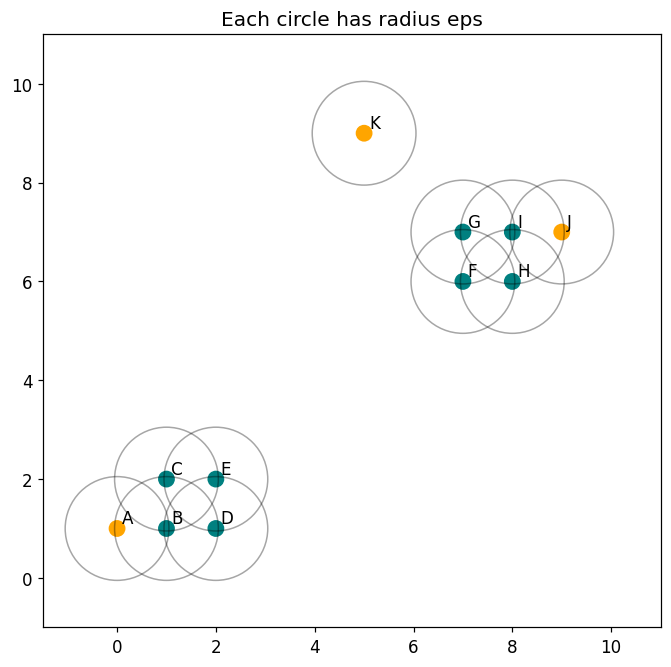

In [4]:
from scipy.spatial.distance import cdist
from matplotlib.patches import Circle
eps = 1.05
min_samples = 3
D = cdist(X,X)
neighbors = [np.flatnonzero(row <= eps) for row in D]
core = np.array([len(indices)>=min_samples for indices in neighbors])
display(pd.DataFrame({'Point':names,'Neighbors':[' '.join(names[v]) for v in neighbors],
                      'Count including self':[len(v) for v in neighbors],'Core':core}))
fig, ax = plt.subplots(figsize=(9,7))
ax.scatter(*X.T,c=np.where(core,'teal','orange'),s=100)
for i,point in enumerate(X):
    ax.add_patch(Circle(point,eps,fill=False,alpha=.35))
    ax.annotate(names[i],point+.1)
ax.set_aspect('equal'); ax.set(xlim=(-1.5,11),ylim=(-1,11),title='Each circle has radius eps')
plt.show()


## 2. Follow the expansion queue
Visit an unvisited point. If it is core, start a group and add its neighbors to a queue. Each core point reached adds its own neighbors. Border points join the group without expanding it.

Gray points in intermediate plots can be unvisited or provisionally noise. The event table distinguishes these cases. Previously marked noise can join a later group as a border point.

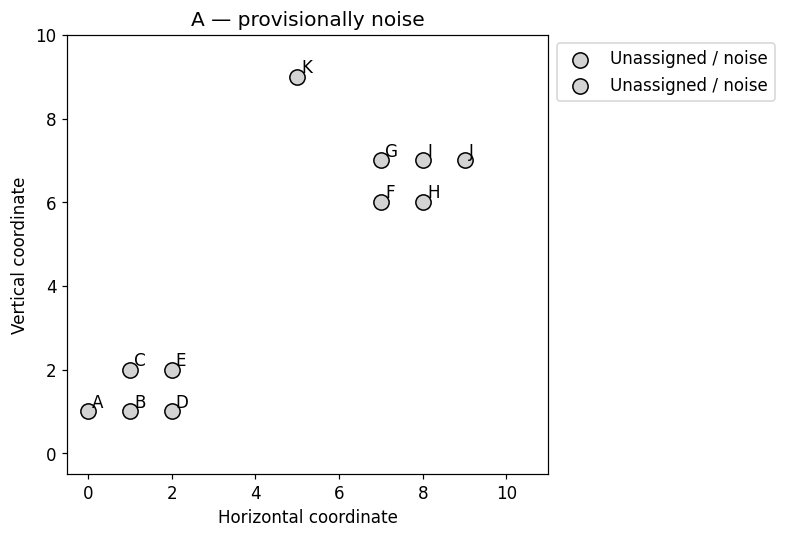

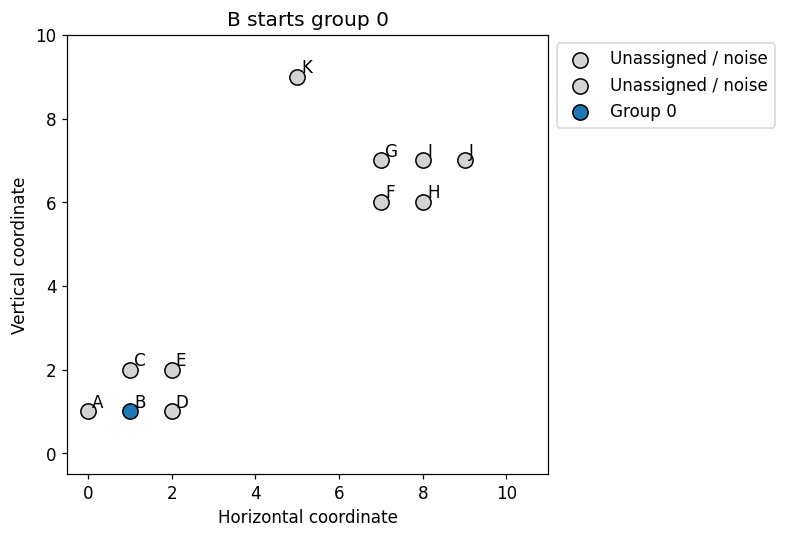

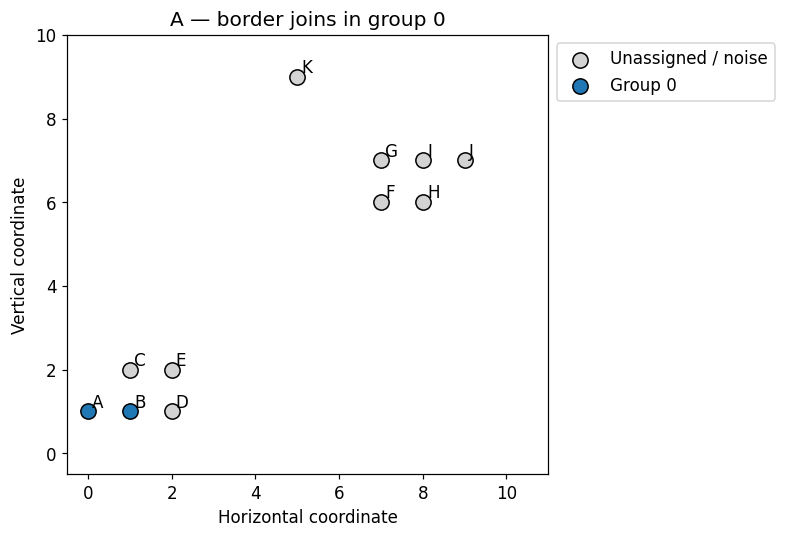

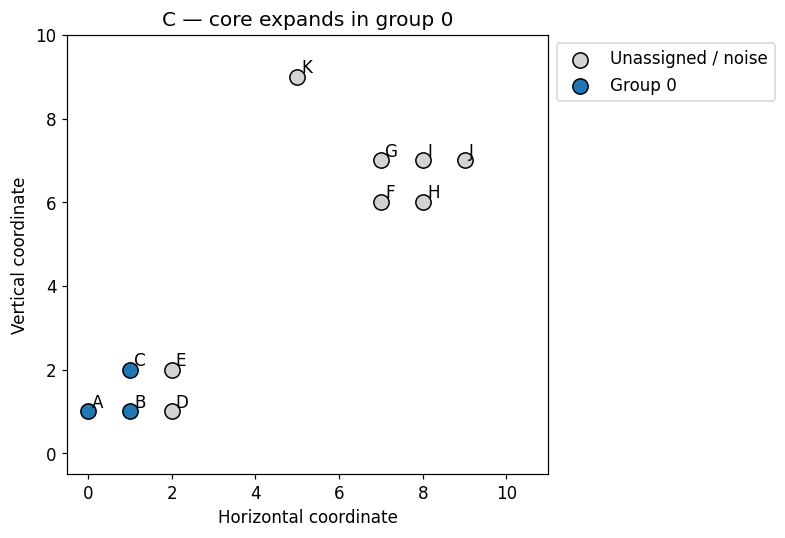

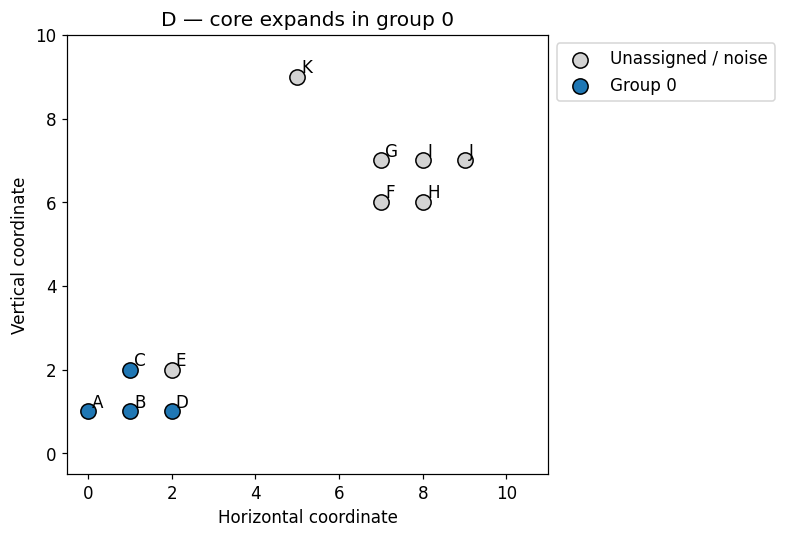

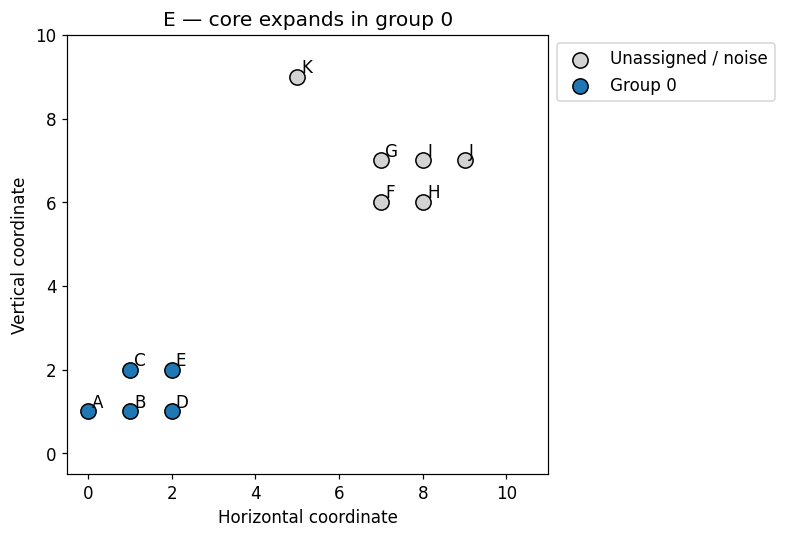

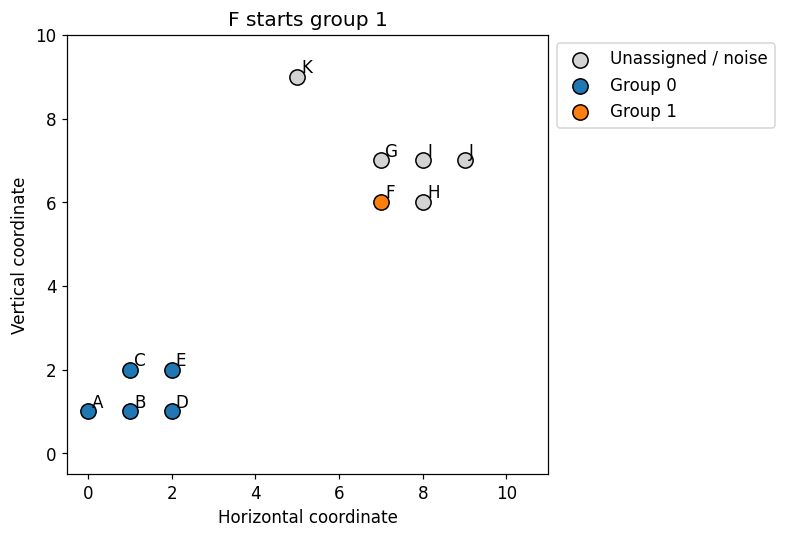

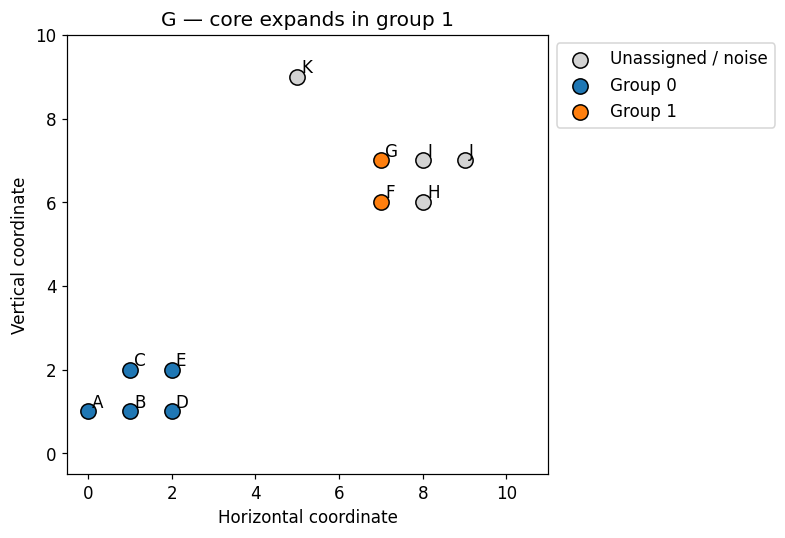

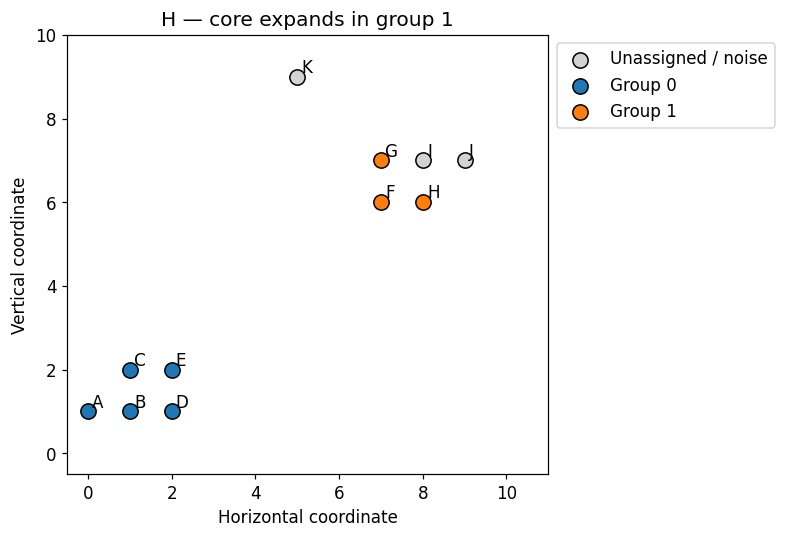

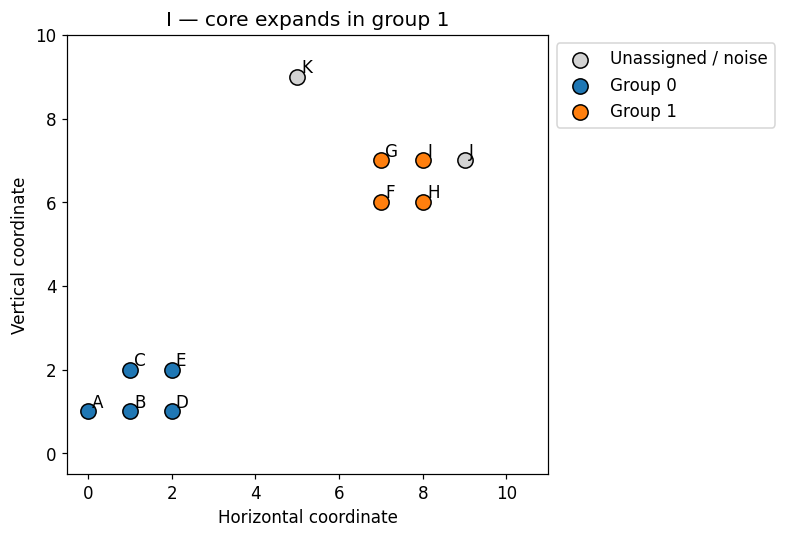

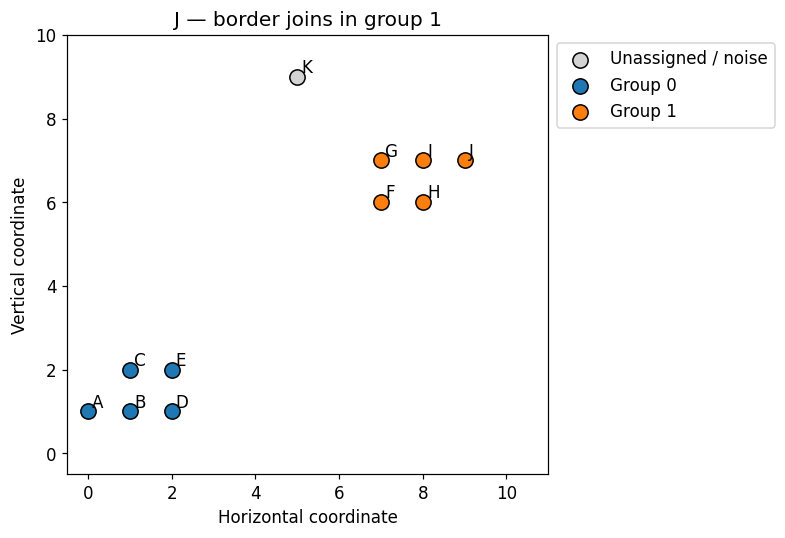

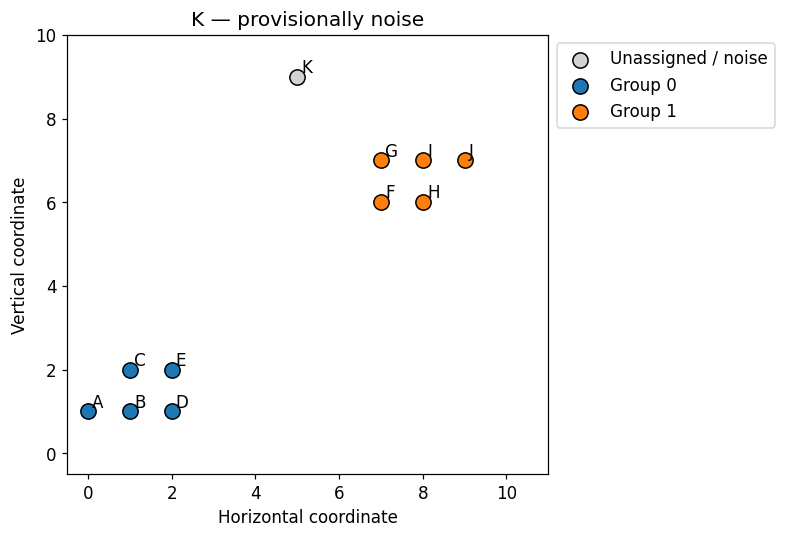

,Point,Action,Remaining queue
0,A,Provisionally noise,
1,B,Start group 0,A B C D
2,A,border joins,B C D
3,C,core expands,D E
4,D,core expands,E
5,E,core expands,
6,F,Start group 1,F G H
7,G,core expands,H I
8,H,core expands,I
9,I,core expands,J


,Point,Group,Status
0,A,0,Border
1,B,0,Core
2,C,0,Core
3,D,0,Core
4,E,0,Core
5,F,1,Core
6,G,1,Core
7,H,1,Core
8,I,1,Core
9,J,1,Border


In [5]:
from collections import deque
UNVISITED, NOISE = -2, -1
labels = np.full(len(X),UNVISITED,dtype=int)
visited = np.zeros(len(X),dtype=bool)
events = []
group = 0
for seed in range(len(X)):
    if visited[seed]: continue
    visited[seed] = True
    if not core[seed]:
        labels[seed] = NOISE
        events.append([names[seed],'Provisionally noise',''])
        plot_groups(X,labels,f'{names[seed]} — provisionally noise')
        continue
    labels[seed] = group
    queue = deque(neighbors[seed].tolist())
    queued = set(neighbors[seed].tolist())
    events.append([names[seed],f'Start group {group}',' '.join(names[list(queue)])])
    plot_groups(X,labels,f'{names[seed]} starts group {group}')
    while queue:
        point = queue.popleft()
        if not visited[point]:
            visited[point] = True
            if core[point]:
                for neighbor in neighbors[point]:
                    if neighbor not in queued:
                        queue.append(int(neighbor)); queued.add(int(neighbor))
        if labels[point] < 0:
            labels[point] = group
            action = 'core expands' if core[point] else 'border joins'
            events.append([names[point],action,' '.join(names[list(queue)])])
            plot_groups(X,labels,f'{names[point]} — {action} in group {group}')
    group += 1
display(pd.DataFrame(events,columns=['Point','Action','Remaining queue']))
status = np.where(labels==-1,'Noise',np.where(core,'Core','Border'))
display(pd.DataFrame({'Point':names,'Group':labels,'Status':status}))


## 3. Verify with scikit-learn
Check the full partition, the noise mask and core-point identities. Group numbering can vary. With ambiguous border points, traversal order can affect which group receives them.

In [6]:
from sklearn.cluster import DBSCAN
model = DBSCAN(eps=eps,min_samples=min_samples).fit(X)
assert adjusted_rand_score(labels,model.labels_) == 1
assert np.array_equal(labels==-1,model.labels_==-1)
assert np.array_equal(np.flatnonzero(core),model.core_sample_indices_)
print('Verified groups, noise and core points.')


Verified groups, noise and core points.


## 4. Change the radius
Predict the outcome for a very small radius and for a radius large enough to connect distant groups. Noise is a result of the chosen parameters and distance representation.

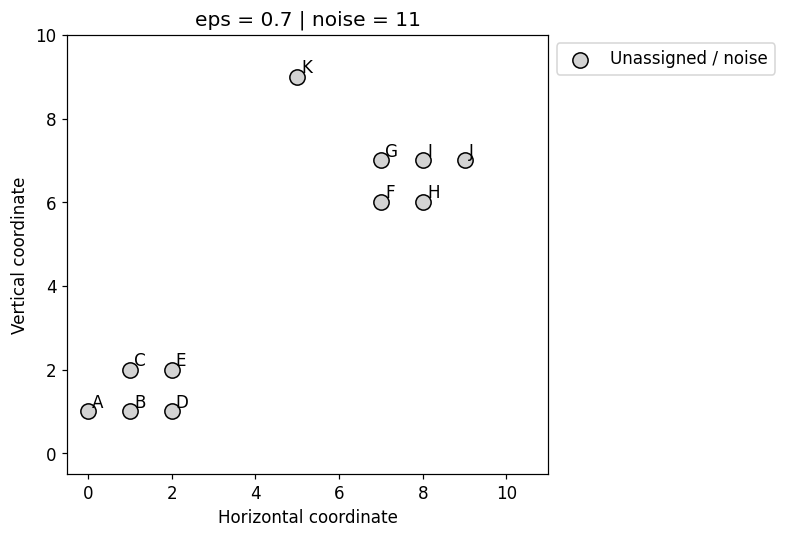

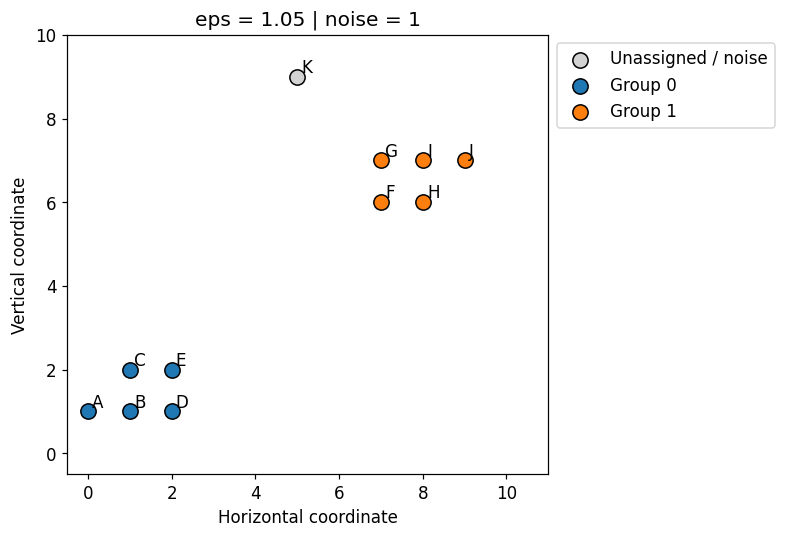

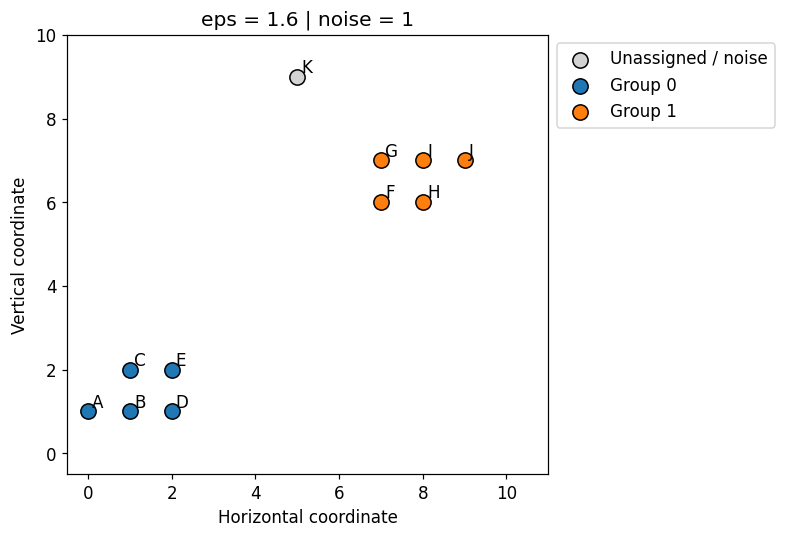

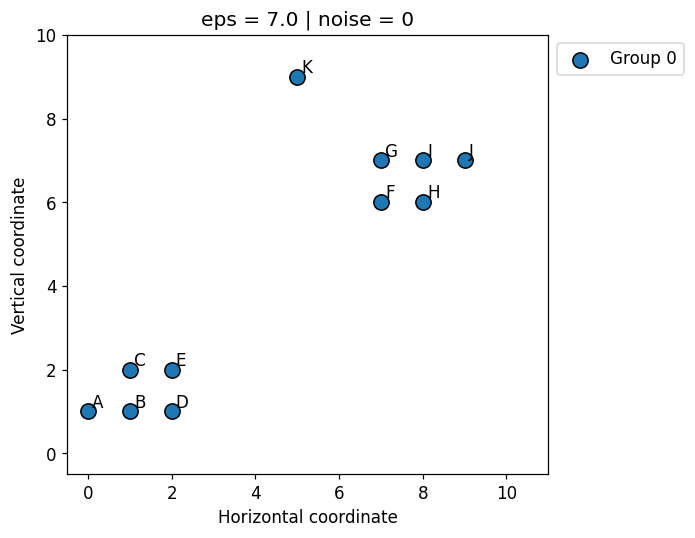

In [7]:
for radius in [.7,1.05,1.6,7.0]:
    result = DBSCAN(eps=radius,min_samples=3).fit_predict(X)
    plot_groups(X,result,f'eps = {radius} | noise = {(result==-1).sum()}')


**Practice** Increase `min_samples` to 4 in section 1 and rerun. Explain why a border point cannot connect two groups by expanding its own neighborhood.

<details><summary>Instructor notes</summary>
At the default settings, A and J are border points and K is noise. A is visited before any core point and is later recovered into the first group. B–E and F–I are core points. DBSCAN does not require a chosen cluster count, but its radius and density threshold still require judgment. A single radius can be unsuitable for populations with very different densities. scikit-learn DBSCAN has no general-purpose `predict` method for new points.
</details>

Reference — [scikit-learn DBSCAN](https://scikit-learn.org/stable/modules/clustering.html#dbscan).